In [1]:
import pandas as pd
import matplotlib.pyplot as plt

h = pd.read_csv("../data/news_history.csv")
h["published"] = pd.to_datetime(h["published"], utc=True,
                                format="%a, %d %b %Y %H:%M:%S GMT", errors="coerce")
h = h[h["published"].dt.year == 2025]

u = h.drop_duplicates(subset="link")
print("Randuri:", len(h), "| Articole unice:", len(u))
print("Date invalide:", h["published"].isna().sum())
print()
print(u.groupby("category").size().sort_values(ascending=False))

Randuri: 12578 | Articole unice: 9559
Date invalide: 0

category
politic           4799
ue                2587
fiscal            1663
banca_centrala     298
extern             113
rating              99
dtype: int64


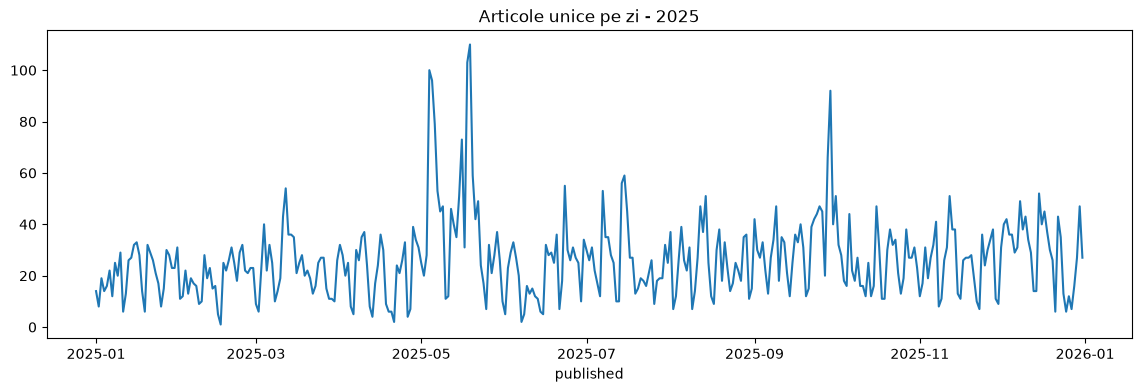

Cele mai agitate 10 zile:
published
2025-05-19    110
2025-05-18    103
2025-05-04    100
2025-05-05     96
2025-09-29     92
2025-05-06     79
2025-05-16     73
2025-09-28     66
2025-07-15     59
2025-05-20     59
dtype: int64


In [2]:
daily = u.groupby(u["published"].dt.date).size()
daily.plot(figsize=(14, 4), title="Articole unice pe zi - 2025")
plt.show()

print("Cele mai agitate 10 zile:")
print(daily.sort_values(ascending=False).head(10))

In [3]:
sources = pd.read_csv("../data/sources.csv")
counts = u["source"].value_counts()
unknown = counts[~counts.index.isin(sources["source"])]
print(f"Surse care nu sunt in sources.csv: {len(unknown)}")
print(unknown.head(30))

Surse care nu sunt in sources.csv: 473
source
RFI                  303
Ziare.com            179
Moldova 1            163
StartupCafe          137
Ziarul Bursa         134
Agerpres             126
G4Media               93
Capital.ro            92
Edupedu.ro            86
Oficiul de Știri      74
Monitorul Cluj        72
Partid AUR            66
Universul.net         65
Vot Corect            62
Q Magazine            59
Radio Moldova         57
Ziarul de Gardă       56
Bihoreanul            52
Jurnalul              48
Agrointeligența       47
StartupCafe.ro        46
Club Feroviar         46
Fanatik.ro            44
Alba24                44
Curs De Guvernare     41
Radio Chișinău        41
TV8.md                38
NewsMaker.md          35
Romania TV            35
BZI.ro                35
Name: count, dtype: int64
